# Multimodal Data Preprocessing: Image Pipeline and Face Recognition Model

**What this notebook does**
1. Load every member's face photos
2. Display them in a grid
3. Augment each photo (rotate, flip, grayscale, brightness)
4. Extract features from every image and save `image_features.csv`
5. Train and evaluate the face recognition model
6. Choose a confidence threshold for rejecting strangers
7. Save the model as `face_model.joblib`

**Photo naming rule:** `name_expression.jpg`, all lowercase, one underscore.
Example: `alice_neutral.jpg`, `alice_smiling.jpg`, `alice_surprised.jpg`

## 0. Setup (Google Colab)
This cell downloads the repo the first time and pulls the latest photos every time after that. Run it first.

In [1]:
import os, subprocess

REPO = "ML_Pipeline_F2_Data_Processing"

# First run in a new Colab session: download the repo
if not os.path.exists(REPO) and not os.getcwd().endswith("notebooks"):
    subprocess.run(["git", "clone", f"https://github.com/ShamiPlacide/ML_Pipeline_F2_Data_Processing"], check=True)

# Move into the notebooks folder (skip if we are already there)
if os.path.exists(REPO):
    os.chdir(f"ML_Pipeline_F2_Data_Processing/notebooks")

# Get the newest photos teammates have pushed
print(subprocess.run(["git", "pull"], capture_output=True, text=True).stdout)
print("Working folder:", os.getcwd())

Already up to date.

Working folder: /content/ML_Pipeline_F2_Data_Processing/notebooks


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance
from skimage.feature import hog

In [3]:
# Where things live (relative to where this notebook is run)
ORIGINAL_DIR  = Path("../media/images")    # input photos
AUGMENTED_DIR = Path("../media/images/augmented")    # augmented photos get saved here
OUTPUT_CSV    = Path("../data/processed/image_features.csv")
FIGURES_DIR   = Path("../reports/figures")

EXPRESSIONS = ["neutral", "smiling", "surprised"]
IMG_SIZE    = (128, 128)   # every image is resized to this before feature extraction
HIST_BINS   = 8            # number of bins per color channel in the histogram

# Create output folders if they don't exist yet
for folder in [AUGMENTED_DIR, OUTPUT_CSV.parent, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

## 1. Load the images
For each file: skip it if it's not a photo, read the member and expression from the filename, open the picture, and store everything in a list called `records`.

In [4]:
records = []

for path in sorted(ORIGINAL_DIR.glob("*")):
    # skip anything that isn't a picture
    if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue

    # "alice_smiling.jpg" -> ["alice", "smiling"]
    parts = path.stem.lower().split("_")
    if len(parts) != 2 or parts[1] not in EXPRESSIONS:
        print(f"[skip] {path.name} does not match <member>_<expression>")
        continue

    member, expression = parts

    # open the photo; exif_transpose fixes phone photos stored sideways;
    # convert("RGB") makes sure all images have the same 3 colour channels
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")

    records.append({"member": member, "expression": expression,
                    "path": path, "image": img})

print(f"Loaded {len(records)} images from {len({r['member'] for r in records})} members")

Loaded 9 images from 3 members


In [5]:
# Check: every member should have all 3 expressions
check = pd.DataFrame(records).groupby("member")["expression"].apply(sorted)
print(check)

for m, exprs in check.items():
    missing = set(EXPRESSIONS) - set(exprs)
    if missing:
        print(f"WARNING: {m} is missing {missing}")

member
denyse     [neutral, smiling, surprised]
nick       [neutral, smiling, surprised]
placide    [neutral, smiling, surprised]
Name: expression, dtype: object


## 2. Display sample pictures
One row per member, one column per expression.

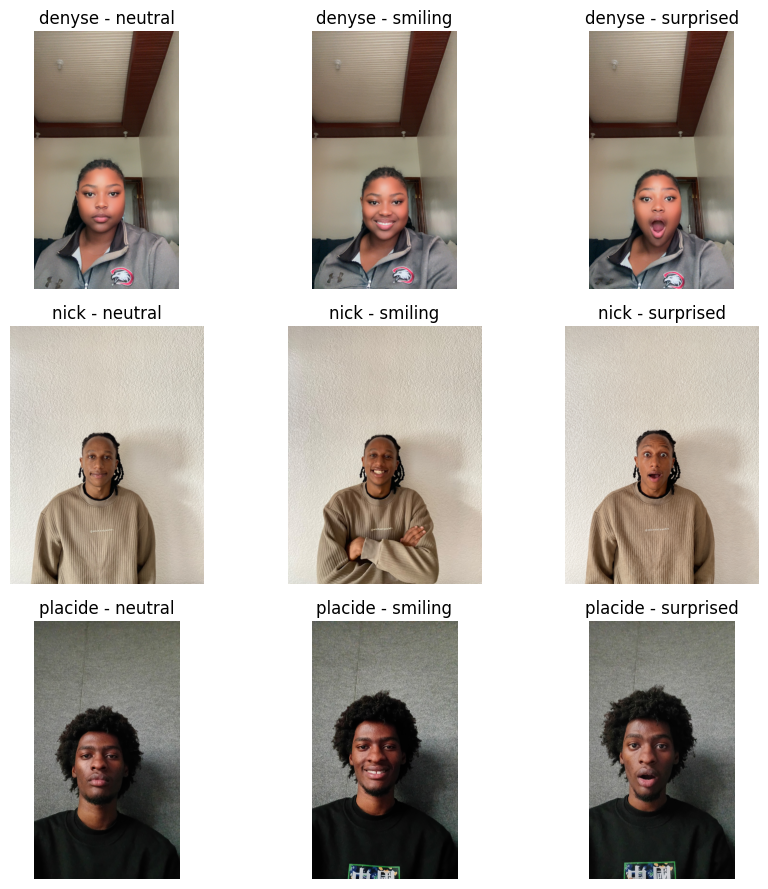

In [7]:
members = sorted({r["member"] for r in records})
lookup = {(r["member"], r["expression"]): r["image"] for r in records}

fig, axes = plt.subplots(len(members), 3, figsize=(9, 3 * len(members)), squeeze=False)

for i, m in enumerate(members):
    for j, e in enumerate(EXPRESSIONS):
        ax = axes[i][j]
        ax.axis("off")
        if (m, e) in lookup:          # only draw if the photo exists
            ax.imshow(lookup[(m, e)])
        ax.set_title(f"{m} - {e}")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "image_samples.png", dpi=150)
plt.show()

## 3. Augmentation
Augmentation creates modified copies of each photo. This gives the face model more training examples and makes it handle small changes in angle and light.

| Name | What it does |
|---|---|
| rot15 / rot-15 | rotate 15 degrees left / right |
| flip | mirror left-to-right |
| gray | convert to grayscale |
| bright / dark | make brighter / darker |

In [8]:
AUGMENTATIONS = {
    "rot15":  lambda im: im.rotate(15,  fillcolor=(0, 0, 0)),
    "rot-15": lambda im: im.rotate(-15, fillcolor=(0, 0, 0)),
    "flip":   lambda im: ImageOps.mirror(im),
    "gray":   lambda im: ImageOps.grayscale(im).convert("RGB"),
    "bright": lambda im: ImageEnhance.Brightness(im).enhance(1.4),
    "dark":   lambda im: ImageEnhance.Brightness(im).enhance(0.6),
}

all_images = []   # originals + augmented copies

for r in records:
    # keep the original, marked as such
    all_images.append({**r, "augmentation": "none", "is_original": True,
                       "source_image": r["path"].name})

    # make each augmented copy, save it to disk, and add it to the list
    for name, fn in AUGMENTATIONS.items():
        aug = fn(r["image"])
        aug_path = AUGMENTED_DIR / f"{r['path'].stem}_{name}.jpg"
        aug.save(aug_path)
        all_images.append({"member": r["member"], "expression": r["expression"],
                           "path": aug_path, "image": aug,
                           "augmentation": name, "is_original": False,
                           "source_image": r["path"].name})

print(f"{len(records)} originals -> {len(all_images)} images in total")

9 originals -> 63 images in total


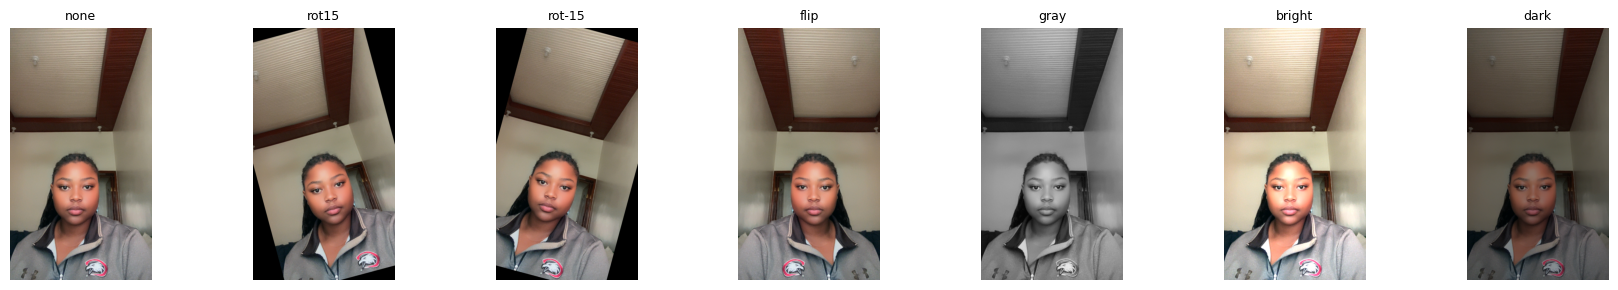

In [9]:
# Show one original next to all of its augmentations
first = records[0]["path"].name
group = [r for r in all_images if r["source_image"] == first]

fig, axes = plt.subplots(1, len(group), figsize=(2.5 * len(group), 3))
for ax, r in zip(axes, group):
    ax.imshow(r["image"])
    ax.set_title(r["augmentation"], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "augmentations.png", dpi=150)
plt.show()

## 4. Feature extraction
Models can't read pictures directly, so we turn each image into a row of numbers.

| Feature | What it captures |
|---|---|
| Intensity stats | average brightness and contrast |
| Color histogram | how much of each colour (R, G, B) the image contains |
| HOG | shapes and edges (face outline, eyes, mouth) |

In [10]:
def color_histogram(img):
    # count pixels in HIST_BINS ranges for each of R, G, B
    arr = np.asarray(img)
    feats = []
    for c in range(3):
        counts, _ = np.histogram(arr[..., c], bins=HIST_BINS, range=(0, 256))
        feats.append(counts / counts.sum())   # turn counts into proportions
    return np.concatenate(feats)

def hog_features(img):
    # HOG works on grayscale; it measures edge directions in small cells
    gray = np.asarray(ImageOps.grayscale(img))
    return hog(gray, orientations=9, pixels_per_cell=(32, 32),
               cells_per_block=(2, 2), feature_vector=True)

def extract_features(img):
    img = img.resize(IMG_SIZE)                       # same size for every image
    gray = np.asarray(ImageOps.grayscale(img), dtype=float)

    feats = {"mean_intensity": gray.mean(), "std_intensity": gray.std()}
    for i, v in enumerate(color_histogram(img)):
        feats[f"hist_{i}"] = v
    for i, v in enumerate(hog_features(img)):
        feats[f"hog_{i}"] = v
    return feats

In [11]:
# quick test on a single image
test = extract_features(records[0]["image"])
print(f"{len(test)} features for one image")

350 features for one image


## 5. Build and save `image_features.csv`
One row per image (originals and augmented), with labels first and features after.

Columns `member`, `expression`, `augmentation`, `is_original`, `source_image` are the labels.
`source_image` is the original photo each row came from. Whoever trains the face model must **split train/test by `source_image`** so copies of the same photo never land on both sides.

In [12]:
rows = []
for r in all_images:
    row = {"member": r["member"], "expression": r["expression"],
           "augmentation": r["augmentation"], "is_original": r["is_original"],
           "source_image": r["source_image"], "image_path": str(r["path"])}
    row.update(extract_features(r["image"]))
    rows.append(row)

df = pd.DataFrame(rows)
df.to_csv(OUTPUT_CSV, index=False)
print(f"Saved {df.shape[0]} rows x {df.shape[1]} columns to {OUTPUT_CSV}")

Saved 63 rows x 356 columns to ../data/processed/image_features.csv


In [13]:
# Final checks
print(df[["member", "expression", "augmentation", "is_original"]].head(10))
print()
print("Rows per member:")
print(df["member"].value_counts())
print()
print("Missing values:", df.isna().sum().sum())

   member expression augmentation  is_original
0  denyse    neutral         none         True
1  denyse    neutral        rot15        False
2  denyse    neutral       rot-15        False
3  denyse    neutral         flip        False
4  denyse    neutral         gray        False
5  denyse    neutral       bright        False
6  denyse    neutral         dark        False
7  denyse    smiling         none         True
8  denyse    smiling        rot15        False
9  denyse    smiling       rot-15        False

Rows per member:
member
denyse     21
nick       21
placide    21
Name: count, dtype: int64

Missing values: 0


## 6. Face recognition model

**Goal:** given a face photo, say which member it is.

**Avoiding leakage:** every photo has 7 rows (the original plus 6 augmented copies). If we split rows randomly, a copy of a photo could land in training while the original lands in testing, and the scores would look better than they really are. We split by **photo** (`source_image`) instead, so all 7 versions of a photo stay on the same side.

**First test:** hold out every member's *smiling* photo, train on the neutral and surprised photos.

In [14]:
df = pd.read_csv(OUTPUT_CSV)

# Hold out the smiling photo of each person for testing.
# All 7 versions of that photo (original + 6 augmentations) go to the test side.
test_mask = df["expression"] == "smiling"
train = df[~test_mask]
test = df[test_mask]

print("Train rows:", len(train), "| Test rows:", len(test))
print("Train photos:", train["source_image"].nunique(),
      "| Test photos:", test["source_image"].nunique())
print("Photos in both sets:",
      set(train["source_image"]) & set(test["source_image"]))   # must be empty

Train rows: 42 | Test rows: 21
Train photos: 6 | Test photos: 3
Photos in both sets: set()


In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss

# Feature columns = everything except the label/info columns
label_cols = ["member", "expression", "augmentation", "is_original",
              "source_image", "image_path"]
feature_cols = [c for c in df.columns if c not in label_cols]

X_train, y_train = train[feature_cols], train["member"]
X_test,  y_test  = test[feature_cols],  test["member"]

# Train
face_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
face_model.fit(X_train, y_train)

# Evaluate on the held-out smiling photos
pred = face_model.predict(X_test)
proba = face_model.predict_proba(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print("F1 (macro):", f1_score(y_test, pred, average="macro"))
print("Log loss:", log_loss(y_test, proba, labels=face_model.classes_))

Accuracy: 1.0
F1 (macro): 1.0
Log loss: 0.004563601208220673


## 7. Evaluation: leave one expression out
One test on one split is shaky with so few photos. Here every expression takes a turn as the test set (train on the other two), and the three results are averaged. The confusion matrix rows are the real person and the columns are the model's guess.

In [16]:
from sklearn.metrics import confusion_matrix

for held in EXPRESSIONS:
    tr = df[df["expression"] != held]
    te = df[df["expression"] == held]

    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    m.fit(tr[feature_cols], tr["member"])
    p = m.predict(te[feature_cols])

    print(f"Held out: {held:10s} accuracy = {accuracy_score(te['member'], p):.2f}")
    print(confusion_matrix(te["member"], p, labels=m.classes_))

Held out: neutral    accuracy = 1.00
[[7 0 0]
 [0 7 0]
 [0 0 7]]
Held out: smiling    accuracy = 1.00
[[7 0 0]
 [0 7 0]
 [0 0 7]]
Held out: surprised  accuracy = 1.00
[[7 0 0]
 [0 7 0]
 [0 0 7]]


In [17]:
results = []
for held in EXPRESSIONS:
    tr = df[df["expression"] != held]
    te = df[df["expression"] == held]

    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    m.fit(tr[feature_cols], tr["member"])
    p = m.predict(te[feature_cols])
    pr = m.predict_proba(te[feature_cols])

    results.append({
        "held_out": held,
        "accuracy": accuracy_score(te["member"], p),
        "f1_macro": f1_score(te["member"], p, average="macro"),
        "log_loss": log_loss(te["member"], pr, labels=m.classes_),
    })

results_df = pd.DataFrame(results)
print(results_df.round(3))
print()
print("Average:")
print(results_df[["accuracy", "f1_macro", "log_loss"]].mean().round(3))

    held_out  accuracy  f1_macro  log_loss
0    neutral       1.0       1.0     0.007
1    smiling       1.0       1.0     0.005
2  surprised       1.0       1.0     0.003

Average:
accuracy    1.000
f1_macro    1.000
log_loss    0.005
dtype: float64


## 8. Confidence threshold
The model always names someone, even for a stranger. We reject any prediction whose top confidence is below a **threshold**.

1. Record the confidence on members' photos (held-out expressions).
2. Record the confidence on *strangers*, simulated by training without one member and testing on that member.
3. Compare the two across candidate thresholds.

In [18]:
rows = []
for held in EXPRESSIONS:
    tr = df[df["expression"] != held]
    te = df[df["expression"] == held]

    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    m.fit(tr[feature_cols], tr["member"])
    p = m.predict(te[feature_cols])
    conf = m.predict_proba(te[feature_cols]).max(axis=1)   # top confidence per row

    rows.append(pd.DataFrame({"held_out": held, "member": te["member"].values,
                              "predicted": p, "confidence": conf,
                              "correct": p == te["member"].values}))

conf_df = pd.concat(rows)
print(conf_df.groupby(["held_out", "member"])
             .agg(confidence=("confidence", "mean"), correct=("correct", "mean"))
             .round(3))

                   confidence  correct
held_out  member                      
neutral   denyse        0.995      1.0
          nick          0.998      1.0
          placide       0.987      1.0
smiling   denyse        0.999      1.0
          nick          0.990      1.0
          placide       0.998      1.0
surprised denyse        0.999      1.0
          nick          0.996      1.0
          placide       0.998      1.0


In [19]:
stranger_rows = []
for stranger in df["member"].unique():
    tr = df[df["member"] != stranger]      # train WITHOUT this person
    te = df[df["member"] == stranger]      # this person is the "stranger"

    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    m.fit(tr[feature_cols], tr["member"])
    conf = m.predict_proba(te[feature_cols]).max(axis=1)

    stranger_rows.append({"stranger": stranger,
                          "mean_conf": conf.mean(),
                          "min_conf": conf.min(),
                          "max_conf": conf.max()})

print(pd.DataFrame(stranger_rows).round(3))

  stranger  mean_conf  min_conf  max_conf
0   denyse      0.927     0.679     0.996
1     nick      0.893     0.574     0.982
2  placide      0.810     0.559     0.910


In [20]:
# Member confidences (from the held-out expression tests)
member_conf = conf_df["confidence"].values
member_ok = conf_df["correct"].values

# Stranger confidences (leave-one-person-out)
stranger_conf = []
for stranger in df["member"].unique():
    tr = df[df["member"] != stranger]
    te = df[df["member"] == stranger]
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    m.fit(tr[feature_cols], tr["member"])
    stranger_conf.extend(m.predict_proba(te[feature_cols]).max(axis=1))
stranger_conf = np.array(stranger_conf)

print("threshold | members accepted correctly | strangers rejected")
for t in [0.90, 0.93, 0.95, 0.97, 0.98, 0.99]:
    members_ok = ((member_conf >= t) & member_ok).mean()
    strangers_rejected = (stranger_conf < t).mean()
    print(f"  {t:.2f}    |        {members_ok:.2f}                |      {strangers_rejected:.2f}")

threshold | members accepted correctly | strangers rejected
  0.90    |        1.00                |      0.54
  0.93    |        1.00                |      0.62
  0.95    |        1.00                |      0.65
  0.97    |        1.00                |      0.67
  0.98    |        0.95                |      0.84
  0.99    |        0.90                |      0.94


**Chosen threshold: 0.99.** See the table above for the trade-off: a higher threshold rejects more strangers but accepts fewer real members.

**Limitation:** the features describe the whole photo, including the background, not just the face. Two people with similar backgrounds can be confused, and no threshold catches that. Cropping to the face or using face embeddings would improve this.

## 9. Train the final model and save it
The final model is trained on **all** photos so it has seen every expression of every member. The file also stores the feature column list and the threshold, so `predict.py` can use all three together.

In [21]:
import joblib

THRESHOLD = 0.99

# Final model: train on ALL photos (every expression, every member)
final_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
final_model.fit(df[feature_cols], df["member"])

# Bundle everything predict.py will need into one file
bundle = {
    "model": final_model,
    "feature_cols": feature_cols,
    "threshold": THRESHOLD,
    "classes": list(final_model.classes_),
}

Path("../models").mkdir(exist_ok=True)
joblib.dump(bundle, "../models/face_model.joblib")
print("Saved. Members:", bundle["classes"], "| threshold:", THRESHOLD)

Saved. Members: ['denyse', 'nick', 'placide'] | threshold: 0.99


## 10. Test the saved model
First three known members (should be accepted), then an unauthorized photo (should be rejected).

In [22]:
!python ../src/face_predict.py ../media/images/denyse_smiling.JPG
!python ../src/face_predict.py ../media/images/nick_smiling.JPG
!python ../src/face_predict.py ../media/images/placide_smiling.jpg

denyse (confidence 1.000)
nick (confidence 0.999)
placide (confidence 0.999)


In [23]:
!python ../src/face_predict.py ../media/images/unauthorized/random_face.png


unknown (confidence 0.969)


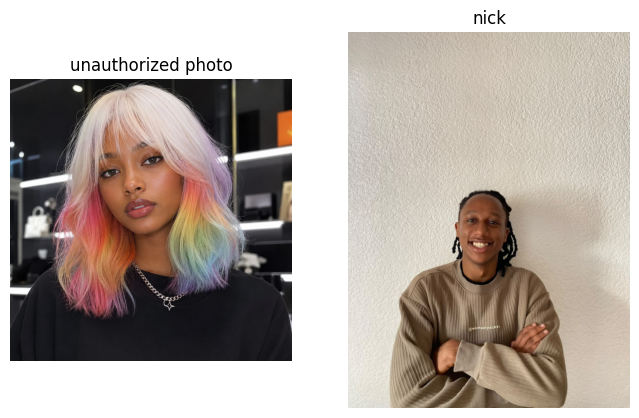

In [24]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(8, 5))
ax[0].imshow(ImageOps.exif_transpose(Image.open("../media/demo/demo_random_face.png")))
ax[0].set_title("unauthorized photo")
ax[1].imshow(ImageOps.exif_transpose(Image.open("../media/images/nick_smiling.JPG")))
ax[1].set_title("nick")
for a in ax: a.axis("off")
plt.show()

## Summary
- **Members:** denyse, nick, placide (3)
- **Original images:** 9 (neutral, smiling, surprised per member)
- **Augmentations:** rotation (+/-15 deg), horizontal flip, grayscale, brighter, darker
- **Total images after augmentation:** 63 (21 per member)
- **Features per image:** 350 (2 intensity stats + 24 color histogram + 324 HOG)
- **Output:** `data/processed/image_features.csv`
- **Face model:** Logistic Regression with scaling, evaluated by leaving one expression out
  - Accuracy 1.0 and F1 (macro) 1.0 for every held-out expression, average log loss 0.005
  - Earlier weakness: a blurry smiling photo was matched to another member (accuracy 0.67); fixed by retaking the photo
  - Only 3 test photos per expression, so these scores are rough estimates
- **Threshold:** 0.99 (90% of member photos accepted, 94% of simulated strangers rejected)
- **Unauthorized test:** the unauthorized photo is rejected as `unknown` (confidence 0.969, below the 0.99 threshold), while all three members are accepted (confidence 0.999 to 1.000)
- **Known limitation:** this was tested with only one unauthorized photo, which looks very different from every member, so it is an easy case. The features describe the whole image (including background and clothing), not just the face, so a stranger with a similar background could be accepted. Cropping to the face or using face embeddings would make this more reliable
- **Saved model:** `models/face_model.joblib`

## Download your results
Colab deletes its files when the session ends, so download these and upload them to GitHub.

In [26]:
from google.colab import files
import shutil

files.download("../models/face_model.joblib")
files.download("../data/processed/image_features.csv")

shutil.make_archive("figures_bundle", "zip", "../reports", "figures")
files.download("figures_bundle.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>